# Paper figures

A small set of figures sized for MNRAS: single column 84 mm (3.32 in), double column 177 mm (6.97 in). Fonts are serif at 7–8 pt, matching the journal text, and every figure is written as a vector PDF to `results/figures/paper/`.

**Data.** Everything is read from the tables exported by `augmentation_results.ipynb` (`results/tables/`) and from the gallery arrays saved by `augmentation_gallery.ipynb`. **Re-run those two notebooks first** whenever new runs finish; this notebook only plots. All numbers are on the **test split**.

| figure | content | place |
|---|---|---|
| 1 | one galaxy under each augmentation | main (methods) |
| 2 | full data: every policy, with and without the symmetries, vs Walmsley | main |
| 3 | full data: strength of the policies (random-crop modality) | main |
| 4 | training-set-size sweep: gain in mean accuracy over H/V flip + rotation + random crop | main (headline) |
| 5 | per-question gain over Walmsley at 1%, 5% … 100% | main |

Section *Recommendations for the existing figures* at the end lists which notebook figures are worth an appendix.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D

TABLES = Path("results/tables")
GALLERY = Path("results/figures/gallery")
OUT_DIR = Path("results/figures/paper")
OUT_DIR.mkdir(parents=True, exist_ok=True)
COL, PAGE = 3.32, 6.97                     # MNRAS column and page widths (inches)
EXCLUDE_FRACTIONS = []                     # e.g. [0.5] to hide a fraction that is still incomplete

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"],   # Times-style, bundled with matplotlib:
                                                                         # identical on every node
    "mathtext.fontset": "stix", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "legend.fontsize": 6.5, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "lines.linewidth": 1.1, "lines.markersize": 4,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.4, "axes.axisbelow": True,
})

# one colour per family, the same as in the analysis notebook
FAMILIES = ["randaugment", "autoaugment", "trivialaugment", "augmix", "cutmix", "mixup"]
COLOR = {"randaugment": "#2a78d6", "autoaugment": "#eb6834", "trivialaugment": "#1baf7a", "augmix": "#eda100",
         "cutmix": "#e87ba4", "mixup": "#008300"}
LABEL = {"randaugment": "RandAugment", "autoaugment": "AutoAugment", "trivialaugment": "TrivialAugment",
         "augmix": "AugMix", "cutmix": "CutMix", "mixup": "MixUp"}
STEM = {"randaugment": "rand_augment_all_ops", "autoaugment": "auto_augment", "trivialaugment": "trivial_augment",
        "augmix": "augmix", "cutmix": "cutmix", "mixup": "mixup"}            # run-name stem at standard strength
WALMSLEY, INK, INK2 = "#4a3aa7", "#1a1a1a", "#5f5e5a"
MARK = {"rc": "o", "wt": "^"}
DIVERGING = LinearSegmentedColormap.from_list("rgb", ["#a52c2b", "#e34948", "#f0efec", "#2a78d6", "#1c5cab"])
QSHORT = {"smooth_or_featured": "smooth/featured", "disk_edge_on": "edge-on", "has_spiral_arms": "spiral arms",
          "bar": "bar", "bulge_size": "bulge size", "how_rounded": "roundness", "edge_on_bulge": "edge-on bulge",
          "spiral_winding": "arm winding", "spiral_arm_count": "arm count", "merging": "merging"}
TASKS = list(QSHORT)


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(OUT_DIR / f"{name}.{ext}")
    print(f"saved {OUT_DIR}/{name}.pdf  ({fig.get_size_inches()[0]:.2f} x {fig.get_size_inches()[1]:.2f} in)")


per_run = pd.read_csv(TABLES / "per_run.csv", dtype={"seed": str})
sweep = pd.read_csv(TABLES / "sweep_per_run.csv", dtype={"seed": str})
sweep = sweep[~sweep["fraction"].isin(EXCLUDE_FRACTIONS)]
for f in ("per_run.csv", "sweep_per_run.csv"):
    print(f"{f:28s} last written {pd.Timestamp((TABLES / f).stat().st_mtime, unit='s'):%Y-%m-%d %H:%M}")
print(f"full-data runs: {len(per_run)}; sweep runs: {(sweep['source'] == 'sweep').sum()} "
      f"at fractions {sorted(sweep.loc[sweep['source'] == 'sweep', 'fraction'].unique())}")


def stats(df, col, by="experiment"):
    g = df.groupby(by)[col]
    return pd.DataFrame({"mean": g.mean(), "std": g.std(), "n": g.count(), "se": g.std() / np.sqrt(g.count())})


full = stats(per_run, "test_total_loss")
w_mean, w_std = full.loc["walmsley_transforms", ["mean", "std"]]

per_run.csv                  last written 2026-10-15 11:48
sweep_per_run.csv            last written 2026-10-15 11:49
full-data runs: 175; sweep runs: 183 at fractions [np.float64(0.01), np.float64(0.05), np.float64(0.2)]


## Figure 1 — the augmentations

*Draft caption:* One galaxy from the validation set under each augmentation studied. **Top row**: the 424×424 original, the random 224×224 crop, and H/V flip + rotation + random crop \citep{walmsley_galaxy_2022}; the network sees 224×224 inputs. **Middle and bottom rows**: the six policies, shown on the 224×224 centre crop with every random op forced to fire so that its effect is visible (in training each op is applied with its own probability). Panel titles give the ops and magnitudes drawn (0–10 scale).


saved results/figures/paper/fig1_augmentations.pdf  (3.32 x 3.92 in)


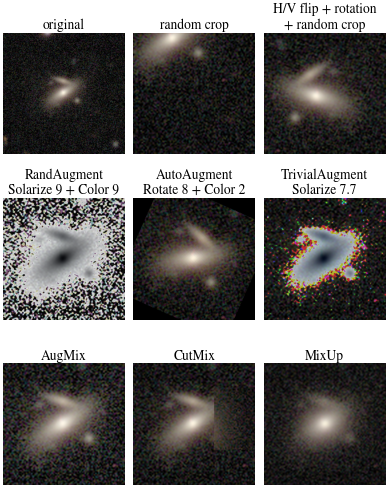

galaxy: J130935.65+155827.9


In [7]:
meta = json.loads((GALLERY / "gallery_galaxy0.json").read_text())
arrs = np.load(GALLERY / "gallery_galaxy0.npz")
panels = {p["name"]: (arrs[p["key"]], p["caption"]) for p in meta["panels"]}
show = [  # (gallery panel name, short title); row 1: original and the two crop modalities, rows 2-3: policies
    ("original (424×424)", "original"),
    ("Random crop 224 (_rc)", "random crop"),
    ("Walmsley transforms (_wt)", "H/V flip + rotation\n+ random crop"),
    ("RandAugment (all ops, N=2, M=9)", "RandAugment"),
    ("AutoAugment (ImageNet policy)", "AutoAugment"),
    ("TrivialAugment (one op, M ~ U[0, 10])", "TrivialAugment"),
    ("AugMix (3 chains, depth 1–3, M=3)", "AugMix"),
    ("CutMix (α=1)", "CutMix"),
    ("MixUp (α=0.2)", "MixUp"),
]
missing = [n for n, _ in show if n not in panels]
assert not missing, f"gallery panels missing (re-run augmentation_gallery.ipynb): {missing}"
nrow = ncol = 3
fig, axes = plt.subplots(nrow, ncol, figsize=(COL, COL * 1.18))     # single column
for ax in axes.flat:
    ax.axis("off")
for ax, (name, title) in zip(axes.flat, show):
    img, cap = panels[name]
    ax.imshow(np.transpose(img, (1, 2, 0)))
    detail = cap.split("\n")[0] if name.startswith(("RandAugment", "AutoAugment", "TrivialAugment")) else ""
    ax.set_title(title + (f"\n{detail}" if detail else ""), fontsize=6.5, pad=2)
fig.subplots_adjust(wspace=0.04, hspace=0.36)
save(fig, "fig1_augmentations")
plt.show()
print("galaxy:", meta["galaxy"])

## Figure 2 — full data: no policy beats the symmetries

*Draft caption:* Test loss with the full training set (mean ± standard deviation over five seeds; lower is better) for each policy at its standard strength, applied after a random crop (circles) or after the physics-preserving horizontal and vertical flips, rotation and random crop of Walmsley et al. (2022) (triangles). The purple line and band show the physics-preserving augmentation alone. Without any augmentation the loss is 21.81, above the plotted range.

saved results/figures/paper/fig2_full_data.pdf  (3.32 x 2.35 in)


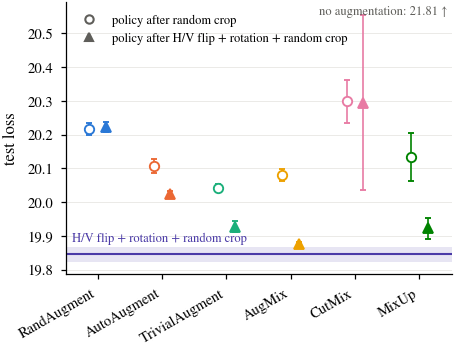

In [3]:
fig, ax = plt.subplots(figsize=(COL, 2.35))
ax.axhspan(w_mean - w_std, w_mean + w_std, color=WALMSLEY, alpha=0.13, lw=0)
ax.axhline(w_mean, color=WALMSLEY, lw=1)
ax.text(-0.4, w_mean + w_std + 0.008, "H/V flip + rotation + random crop", color=WALMSLEY, fontsize=6, va="bottom", ha="left")
off = {"rc": -0.13, "wt": 0.13}
for i, f in enumerate(FAMILIES):
    for m in ("rc", "wt"):
        e = f"{STEM[f]}_{m}"
        if e not in full.index:
            continue
        r = full.loc[e]
        ax.errorbar(i + off[m], r["mean"], yerr=r["std"], fmt=MARK[m], color=COLOR[f], ms=4.5, capsize=1.5,
                    elinewidth=0.8, mfc="white" if m == "rc" else COLOR[f], mec=COLOR[f], mew=0.9)
ax.set_xticks(range(len(FAMILIES)), [LABEL[f] for f in FAMILIES], rotation=30, ha="right")
ax.set_xlim(-0.5, len(FAMILIES) - 0.5)
ax.grid(axis="x", visible=False)
ax.set_ylabel("test loss")
nb = full.loc["baseline_B", "mean"] if "baseline_B" in full.index else np.nan
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=INK2, mfc="white", label="policy after random crop"),
                   Line2D([], [], marker="^", ls="", color=INK2, label="policy after H/V flip + rotation + random crop")],
          loc="upper left", fontsize=6)
ax.annotate(f"no augmentation: {nb:.2f} ↑", xy=(0.99, 0.99), xycoords="axes fraction", ha="right", va="top",
            fontsize=6, color=INK2)
save(fig, "fig2_full_data")
plt.show()

## Figure 3 — stronger is worse

*Draft caption:* Test loss with the full training set for the weak, moderate and strong presets of each policy, applied after a random crop (mean ± standard deviation over five seeds). The standard preset of each policy is the moderate one, except for RandAugment, whose standard (N = 2, M = 9) is its strong preset. The band shows the physics-preserving horizontal and vertical flips, rotation and random crop. No policy improves with strength; for four of the six, the strong preset is significantly worse than the weak one.

saved results/figures/paper/fig3_strength.pdf  (3.32 x 2.35 in)


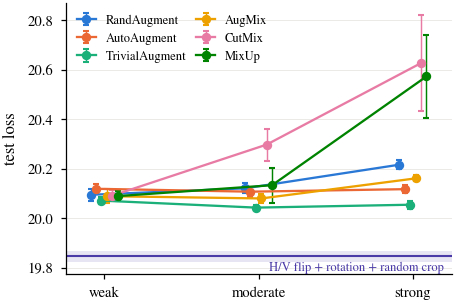

In [4]:
rc = per_run[(per_run["modality"] == "rc") & per_run["family"].isin(FAMILIES)]
st = rc.groupby(["family", "strength"])["test_total_loss"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(COL, 2.35))
ax.axhspan(w_mean - w_std, w_mean + w_std, color=WALMSLEY, alpha=0.13, lw=0)
ax.axhline(w_mean, color=WALMSLEY, lw=1)
order = ["weak", "moderate", "strong"]
for k, f in enumerate(FAMILIES):
    d = st[st["family"] == f].set_index("strength").reindex(order).dropna()
    x = np.array([order.index(s) for s in d.index]) + (k - 2.5) * 0.035
    ax.errorbar(x, d["mean"], yerr=d["std"], color=COLOR[f], marker="o", ms=3.5, capsize=1.5, elinewidth=0.7,
                label=LABEL[f])
ax.set_xticks(range(3), ["weak", "moderate", "strong"])
ax.set_xlim(-0.25, 2.25)
ax.grid(axis="x", visible=False)
ax.set_ylabel("test loss")
ax.legend(ncol=2, loc="upper left", fontsize=6, handlelength=1.5, columnspacing=0.8)
ax.text(2.2, w_mean - 0.02, "H/V flip + rotation + random crop", color=WALMSLEY, fontsize=6, ha="right", va="top")
save(fig, "fig3_strength")
plt.show()

## Figure 4 — the training-set-size sweep (headline)

*Draft caption:* Change in mean test accuracy over the ten Galaxy Zoo questions, in percentage points, relative to the physics-preserving horizontal and vertical flips, rotation and random crop (horizontal line at zero; positive = better), as a function of the number of training galaxies. Each policy is applied **(a)** on top of the horizontal and vertical flips, rotation and random crop or **(b)** after a random crop only. Points are means over five seeds with standard errors. Hollow points at 100 per cent come from the full-data runs, trained with the original schedule. In (b) the black dashed line is the random crop without any policy.

saved results/figures/paper/fig4_sweep_delta.pdf  (6.97 x 2.45 in)


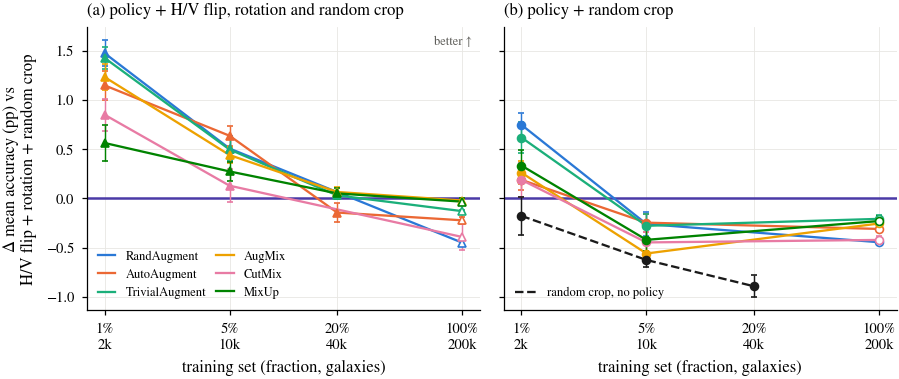

In [5]:
fr_sw = sorted(sweep["fraction"].unique())
METRIC4, SCALE4 = "mean_task_accuracy", 100          # mean accuracy over the ten questions, in per cent
ref = stats(sweep[sweep["experiment"] == "walmsley_transforms"], METRIC4, by="fraction")
ns = sweep.groupby("fraction")["n_train"].first()


def delta_curve(e):
    d = stats(sweep[sweep["experiment"] == e], METRIC4, by="fraction").join(ref, rsuffix="_ref", how="inner")
    d["delta"] = SCALE4 * (d["mean"] - d["mean_ref"])
    d["err"] = SCALE4 * np.sqrt(d["se"].fillna(0) ** 2 + d["se_ref"].fillna(0) ** 2)
    src = sweep[sweep["experiment"] == e].groupby("fraction")["source"].first()
    d["hollow"] = src.reindex(d.index) != "sweep"
    return d


fig, axes = plt.subplots(1, 2, figsize=(PAGE, 2.45), sharey=True)
for ax, m, title in [(axes[0], "wt", "(a) policy + H/V flip, rotation and random crop"), (axes[1], "rc", "(b) policy + random crop")]:
    ax.axhline(0, color=WALMSLEY, lw=1.2)
    curves = [(f"{STEM[f]}_{m}", COLOR[f], LABEL[f]) for f in FAMILIES]
    if m == "rc":
        curves.append(("baseline_rc", INK, "random crop, no policy"))
    for e, c, lab in curves:
        if e not in set(sweep["experiment"]):
            continue
        d = delta_curve(e)
        if d.empty:
            continue
        ax.plot(d.index, d["delta"], color=c, lw=1.1, label=lab, ls="--" if e == "baseline_rc" else "-")
        for fx, r in d.iterrows():
            ax.errorbar(fx, r["delta"], yerr=r["err"], fmt=MARK.get(m, "o"), color=c, ms=3.8, capsize=1.3,
                        elinewidth=0.7, mfc="white" if r["hollow"] else c, mec=c, mew=0.8)
    ax.set_xscale("log")
    ax.set_xticks(fr_sw, [f"{f:.0%}\n{ns[f] / 1000:.0f}k" if ns[f] >= 1000 else f"{f:.0%}\n{ns[f]:.0f}" for f in fr_sw])
    ax.minorticks_off()
    ax.set_title(title, loc="left")
    ax.set_xlabel("training set (fraction, galaxies)")
axes[0].set_ylabel("Δ mean accuracy (pp) vs\nH/V flip + rotation + random crop")
axes[0].text(0.98, 0.97, "better ↑", transform=axes[0].transAxes, fontsize=6, color=INK2, ha="right", va="top")
axes[0].legend(loc="lower left", ncol=2, fontsize=6, handlelength=1.4, columnspacing=0.8)
h2, l2 = axes[1].get_legend_handles_labels()
extra = [(x, y) for x, y in zip(h2, l2) if y == "random crop, no policy"]
if extra:
    axes[1].legend(*zip(*extra), loc="lower left", fontsize=6, handlelength=1.8)
fig.subplots_adjust(wspace=0.06)
save(fig, "fig4_sweep_delta")
plt.show()

## Figure 5 — which questions gain with few labels

*Draft caption:* Change in test accuracy per Galaxy Zoo question, in percentage points, relative to the physics-preserving horizontal and vertical flips, rotation and random crop, for each policy applied on top of them, at each training-set size (blue = better). Every cell is a mean over five seeds. $^{*}$100 per cent: the full-data runs, trained with the original schedule.

saved results/figures/paper/fig5_questions.pdf  (6.97 x 4.40 in)


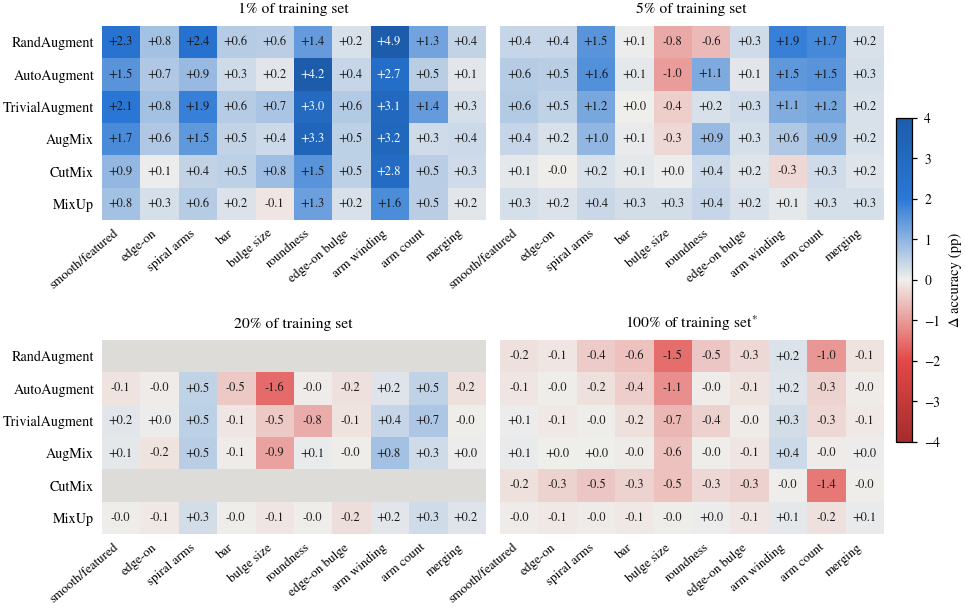

In [6]:
rows = [f"{STEM[f]}_wt" for f in FAMILIES]
# only fractions where the reference and at least one policy have finished (others appear once their runs do)
done_at = sweep.groupby("fraction")["experiment"].apply(set)
fr_q = [f for f in fr_sw if "walmsley_transforms" in done_at[f] and done_at[f] & set(rows)]
skipped = [f for f in fr_sw if f not in fr_q]
if skipped:
    print("figure 5: not shown yet (reference or policies unfinished):", [f"{f:.0%}" for f in skipped])
mats = []
for f in fr_q:
    s = sweep[sweep["fraction"] == f]
    refq = s[s["experiment"] == "walmsley_transforms"][[f"test_{t}_accuracy" for t in TASKS]].mean()
    M = np.full((len(rows), len(TASKS)), np.nan)
    for i, e in enumerate(rows):
        v = s[s["experiment"] == e]
        if len(v):
            M[i] = 100 * (v[[f"test_{t}_accuracy" for t in TASKS]].mean() - refq).to_numpy()
    mats.append(M)
vmax = min(4.0, np.nanmax([np.nanmax(np.abs(M)) for M in mats]))
cmap = DIVERGING.copy()
cmap.set_bad("#dddcd8")
ncols = 2 if len(fr_q) > 1 else 1
nrows = int(np.ceil(len(fr_q) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(PAGE, 2.05 * nrows + 0.3), squeeze=False)
for ax in axes.flat[len(fr_q):]:
    ax.set_visible(False)
for k, (ax, f, M) in enumerate(zip(axes.flat, fr_q, mats)):
    im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, norm=TwoSlopeNorm(0, -vmax, vmax), aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                ax.text(j, i, f"{M[i, j]:+.1f}", ha="center", va="center", fontsize=6,
                        color="white" if abs(M[i, j]) > 0.65 * vmax else INK)
    ax.set_xticks(range(len(TASKS)), [QSHORT[t] for t in TASKS], rotation=40, ha="right", fontsize=6.3)
    ax.set_yticks(range(len(rows)), [LABEL[f] for f in FAMILIES] if k % ncols == 0 else [], fontsize=6.8)
    ax.grid(False)
    ax.tick_params(left=False, bottom=False, length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    src_f = sweep[(sweep["fraction"] == f)]["source"].iloc[0]
    ax.set_title(f"{f:.0%} of training set" + ("$^{*}$" if src_f != "sweep" else ""), fontsize=7.5)
fig.subplots_adjust(wspace=0.04, hspace=0.62)
cb = fig.colorbar(im, ax=[a for a in axes.flat if a.get_visible()], fraction=0.02, pad=0.015)
cb.set_label("Δ accuracy (pp)", fontsize=7)
cb.ax.tick_params(labelsize=6.5)
save(fig, "fig5_questions")
plt.show()

## Recommendations for the existing (notebook) figures

All existing figures stay where they are; these are suggestions for where they could go.

**Worth an appendix**
- `K_sweep_overall`: absolute test loss and mean accuracy against training-set size. Figure 4 shows differences only; a referee will want the absolute numbers once.
- `K_sweep_per_question_wt` / `_rc`: per-question accuracy curves. They back up Figure 5 with absolute values.
- `F_val_loss_curves` and `F_best_epoch`: training dynamics. They show that the full-data `rc`/`wt` runs peak at the end of the cosine schedule (claim C11), a limitation you should state.
- `F_seed_spread`: per-seed variance; supports the statement that strong CutMix and MixUp are unstable (C7).
- `E_family_by_modality`: only if the RandomResizedCrop result stays in the paper. It is the clearest picture of the 2.5–3 loss-point crop effect.
- `C_delta_accuracy_heatmap` (with `MODALITY = "wt"`): per-question differences at full data, if Figure 5 needs a more detailed full-data companion.
- `answer_shares_per_split` (dataset notebook): one figure showing that train, validation and test have the same morphology mix. The tables may be enough.

**Not recommended** (redundant or weak)
- `B_baselines`, `C_ranked_total_loss`: the same information as Figure 2 and the tables.
- `C_delta_rmse_heatmap`: RMSE adds nothing beyond accuracy and loss.
- `D_strength_dose_response`: replaced by Figure 3.
- `E_focus_tasks`: covered by Figure 5.
- `E_wt_gain_vs_geometric_exposure`: six points with a weak correlation (claim C10 is only partly supported). Mention it in the text instead.
- `H_information_destroyed_vs_performance`: the information-destroyed analysis is not in the paper.
- `K_sweep_delta_vs_walmsley`, `K_sweep_question_heatmaps`: replaced by Figures 4 and 5.
- The per-augmentation gallery panels: Figure 1 replaces them. A supplementary-material figure could hold the full gallery.

**Tables instead of figures.** The main numbers (test loss ± std and mean accuracy per experiment and fraction) belong in a table. `results/tables/sweep_summary.tex` and `aggregated.tex` are the starting point.